<a href="https://colab.research.google.com/github/AdelineKwakye/walmart-huricane-project/blob/main/notebooks/scratch/Vi_Nguyen_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**DATA CLEANING**

In [70]:
# what needs to be done:

  # handle duplicates

  # convert unit price from text -> real number

  # decide on whether negatives values are kept ( yes because they indicate returns / refunds )

  # parse timestamp to turn it into date time

  # clean store_id


# import data
import pandas as pd
walmart_transactions = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/walmart_transactions.csv'
store_locations = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/store_locations.csv'
distribution_centers = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/distribution_centers.csv'
df_transactions = pd.read_csv(walmart_transactions)
df_store = pd.read_csv(store_locations)
df_distribution_centers = pd.read_csv(distribution_centers)
df_product = pd.read_csv('https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/product_catalog.csv')


print("Store data\n")
print(df_store.head())
print("transactions sample\n")
print(df_transactions.head(10))
print("distribution centers\n")
display(df_distribution_centers)
print('product catalog\n')
display(df_product)


Store data

  store_id                             store_name          city    state  \
0   FL-239            Walmart Supercenter Orlando       Orlando       FL   
1   FL-105              Walmart Supercenter Tampa         Tampa       FL   
2   FL-330              Walmart Supercenter Miami         Miami       FL   
3   FL-412       Walmart Supercenter Jacksonville  Jacksonville       FL   
4   FL-287  Walmart Neighborhood Market Kissimmee     Kissimmee  Florida   

   zip_code  latitude  longitude   region  
0     32801   28.5383   -81.3792  Central  
1     33602   27.9506   -82.4572     West  
2     33101   25.7617   -80.1918    South  
3     32099   30.3322   -81.6557    North  
4     34741   28.2920   -81.4076  Central  
transactions sample

  transaction_id store_id            timestamp            sku  \
0      TXN012636   FL-710  2024-09-24T09:48:13     PNUTBTR-16   
1      TXN000759   fl-412  2024-09-13 20:30:20      CNSOUP-01   
2      TXN003338   FL-105  2024-09-17 10:06:00  TOI

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


product catalog



,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack
5,WATER24PK,Bottled Water 24-Pack,Emergency,Bottled,2.38,Sara Lee,24 pack
6,WTR_24PK,Water - 24 Pack,Emergency,NaN,2.08,Frito-Lay,1 pack
7,BATT-100,BATTERIES AA 4PK,Emergency Supplies,AA,NaN,3M Company,6 pack
8,BAT-AA4,AA Batteries 4-Pack,Emergency Supplies,AA,4.16,Kimberly-Clark,4pk
9,BATT_AA_4PK,AA Batteries 4-Pack,Emergency,AA,3.71,Anheuser-Busch,24 pack


In [71]:
# setting up decision log
# used same formating from decision log in previous lab
DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)

raw_rows = len(df_transactions)
print('starting with', raw_rows, 'rows')

starting with 25562 rows


In [72]:
# handle duplicate function

def handle_duplicates (df_name):
  before_len = len(df_name) # length before
  print("Length before cleaning duplicates: ", before_len)
  removed = df_name.duplicated().sum() # duplicated rows to be removed
  clean_dup = df_name.drop_duplicates().copy() # drop duplicates
  after_len = len(clean_dup) # length after
  print( "Length after cleaning duplicates: ", after_len)
  log('duplicates', 'dropped exact duplicate rows', removed) # log
  return clean_dup

df_clean = handle_duplicates(df_transactions)
show_log()

Length before cleaning duplicates:  25562
Length after cleaning duplicates:  25532
[duplicates] dropped exact duplicate rows (30 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30


In [93]:
# Drop duplicates in df_transactions in-place as requested
before_txn_len = len(df_transactions)
df_transactions = df_transactions.drop_duplicates().copy()
after_txn_len = len(df_transactions)
print(f"Dropped {before_txn_len - after_txn_len} exact duplicate rows from df_transactions.")
print(f"New df_transactions length: {after_txn_len}")

Dropped 0 exact duplicate rows from df_transactions.
New df_transactions length: 25532


In [74]:
# handle unit price
def clean_unit_price(df_name):
    before_len = len(df_name)
    print("Length before cleaning: ", before_len)
    clean_df = df_name.copy()


    # Strip '$' and convert directly to float
    clean_df['unit_price'] = (
        clean_df['unit_price']
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.strip()
        .astype(float)
    )

    assert clean_df['unit_price'].dtype == float # confirm that it's a float

    after_len = len(clean_df)
    print("Length after cleaning: ", after_len)
    log('unit price', 'stripped $ and converted to float', len(clean_df))
    return clean_df

df_clean = clean_unit_price(df_clean)
show_log()

Length before cleaning:  25532
Length after cleaning:  25532
[unit price] stripped $ and converted to float (25532 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532


In [75]:
# handle negative values
def handle_negative_values(df_name):
  # keeping negative values since representative of refunds/ returns
  # this function will just ensure that quantity is a numeric value

  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()

  clean_df['quantity'] = pd.to_numeric(clean_df['quantity'], errors="coerce") # convert to numeric

  # keep track of negative values
  negative_values = (clean_df['quantity'] < 0 ).sum()
  print("Number of negative values: ", negative_values)

  after_len = len(clean_df)
  print("Length after cleaning: ", after_len)

  log('negative quantity', 'decided to keep all of the negative quantities since it could be indicative of refunds/returns', 0)
  return clean_df

df_clean = handle_negative_values(df_clean)
show_log()

Length before cleaning:  25532
Number of negative values:  130
Length after cleaning:  25532
[negative quantity] decided to keep all of the negative quantities since it could be indicative of refunds/returns (0 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0


In [76]:
# cleaning store_id
def clean_store_id(df_name, table_name):
    before_len = len(df_name)
    print(f"Length before cleaning {table_name}: ", before_len)
    clean_df = df_name.copy()

    # standardize the store id to start with FL-###
    # using format that was done in previous lab/studio
    clean_df['store_id'] = (
        clean_df['store_id']
        .astype(str)
        .str.upper()
        .str.strip()
        .str.replace(r'[^A-Z0-9]', '', regex=True)
        .apply(lambda s: f'{s[:2]}-{s[2:]}')
    )

    after_len = len(clean_df)
    print(f"Length after cleaning {table_name}: ", after_len)

    log(
        f'store_id ({table_name})',
        f'standardized formatting of store_id to follow FL-### in {table_name}',
        len(clean_df),
    )
    return clean_df

df_clean = clean_store_id(df_clean, table_name='transactions') # standardize store id from transactions
df_clean_store = clean_store_id(df_store, table_name='stores') # standardize store id from stores
show_log()

Length before cleaning transactions:  25532
Length after cleaning transactions:  25532
[store_id (transactions)] standardized formatting of store_id to follow FL-### in transactions (25532 row(s))
Length before cleaning stores:  14
Length after cleaning stores:  14
[store_id (stores)] standardized formatting of store_id to follow FL-### in stores (14 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14


In [77]:
# view list of clean store names
print("df_clean store_id samples:\n", df_clean['store_id'].head(3))
print("df_clean_store store_id samples:\n", df_clean_store['store_id'].head(3))

# confirm that the store names match
print(df_clean['store_id'].isin(df_clean_store['store_id']).all())
print(df_clean_store['store_id'].isin(df_clean['store_id']).all())

# view the updated decisions log
show_log()

df_clean store_id samples:
 0    FL-710
1    FL-412
2    FL-105
Name: store_id, dtype: object
df_clean_store store_id samples:
 0    FL-239
1    FL-105
2    FL-330
Name: store_id, dtype: object
True
True


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14


In [78]:
def clean_timestamps(df_name):
  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()

  # standardize the timestamp column so it uses space as a separator and a T

  clean_df['timestamp'] = (
      clean_df['timestamp']
      .astype(str)
      .str.strip()
      .str.replace('T', ' ', regex=False)
  )
  # convert to datetime

  clean_df['timestamp'] = pd.to_datetime(clean_df['timestamp'], format='mixed', errors='coerce')

  null_count = clean_df['timestamp'].isnull().sum()
  print("Number of null values: ", null_count)
  # drop na
  clean_df = clean_df.dropna(subset=['timestamp']).copy()

  # create normalized date column
  clean_df['date'] = clean_df['timestamp'].dt.normalize()

  after_len = len(clean_df)
  print("Length after cleaning, ", after_len)
  log('timestamp', 'standardized the separator, converted to be datetime, droped na values, and created a normalized date column ', null_count)
  return clean_df

print('nulls in df_clean: ', df_clean['timestamp'].isnull().sum())

df_clean = clean_timestamps(df_clean)
print('nulls in df_clean: ', df_clean['timestamp'].isnull().sum())
show_log()



# Check remaining nulls across all columns
print("Remaining nulls per column:")
print(df_clean.isnull().sum())

nulls in df_clean:  884
Length before cleaning:  25532
Number of null values:  884
Length after cleaning,  24648
[timestamp] standardized the separator, converted to be datetime, droped na values, and created a normalized date column  (884 row(s))
nulls in df_clean:  0
Remaining nulls per column:
transaction_id    0
store_id          0
timestamp         0
sku               0
product_name      0
category          0
quantity          0
unit_price        0
date              0
dtype: int64


In [79]:
def profile(df, name='dataset'):
    print(f'=== {name} ===')
    print(f'{len(df):,} rows x {len(df.columns)} columns')
    print()
    summary = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isnull().sum(),
        'null_pct': (100 * df.isnull().mean()).round(1),
        'distinct': df.nunique(),
    })
    print(summary)
    print()
    print('exact duplicate rows:', df.duplicated().sum())
    return summary


    # Final post-cleaning health check
profile(df_clean, name='Cleaned Transactions (df_clean)')

=== Cleaned Transactions (df_clean) ===
24,648 rows x 9 columns

                         dtype  nulls  null_pct  distinct
transaction_id          object      0       0.0     24648
store_id                object      0       0.0        12
timestamp       datetime64[ns]      0       0.0     23417
sku                     object      0       0.0        45
product_name            object      0       0.0        63
category                object      0       0.0        37
quantity                 int64      0       0.0        11
unit_price             float64      0       0.0      1667
date            datetime64[ns]      0       0.0        30

exact duplicate rows: 0


,dtype,nulls,null_pct,distinct
transaction_id,object,0,0.0,24648
store_id,object,0,0.0,12
timestamp,datetime64[ns],0,0.0,23417
sku,object,0,0.0,45
product_name,object,0,0.0,63
category,object,0,0.0,37
quantity,int64,0,0.0,11
unit_price,float64,0,0.0,1667
date,datetime64[ns],0,0.0,30


In [80]:
# clean distribution center csv
  # unnecessary ~ in surge_capacity column
  # Nan value in cost per shipment


print(df_distribution_centers.info())
print(df_distribution_centers.isnull().sum())

def clean_distribution_center(df_name):
  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()
  clean_df['surge_capacity'] = clean_df['surge_capacity'].str.strip().str.replace('~', '', regex=False)
  clean_df['surge_capacity'] = pd.to_numeric(clean_df['surge_capacity'], errors='coerce')

  # Count missing shipping costs
  missing_costs = clean_df['cost_per_shipment'].isna().sum()
  print("Missing shipping costs:", missing_costs)

  # Check for missing shipping costs
  missing_costs = clean_df['cost_per_shipment'].isna().sum()
  print("Missing shipping costs:", missing_costs)

  after_len = len(clean_df)
  ## log
  log('surge capacity', 'striped white spaces, got rid of ~, and converted type to be numeric', after_len)
  log('distribution center missing values', 'kept missing value because there is no reliable information to determine correct value', 0)

  return clean_df

clean_distribution_center_df = clean_distribution_center(df_distribution_centers)
show_log()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   dc_id                   5 non-null      object 
 1   dc_name                 5 non-null      object 
 2   city                    5 non-null      object 
 3   state                   5 non-null      object 
 4   avg_daily_shipments     5 non-null      int64  
 5   surge_capacity          5 non-null      object 
 6   distance_to_orlando_mi  5 non-null      int64  
 7   cost_per_shipment       4 non-null      float64
dtypes: float64(1), int64(2), object(5)
memory usage: 452.0+ bytes
None
dc_id                     0
dc_name                   0
city                      0
state                     0
avg_daily_shipments       0
surge_capacity            0
distance_to_orlando_mi    0
cost_per_shipment         1
dtype: int64
Length before cleaning:  5
Missing shipping costs: 1
Missing 

,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0


In [81]:
#strip product name
df_clean['product_name']=df_clean['product_name'].str.strip()
#lowercase
df_clean['product_name']=df_clean['product_name'].str.lower()
#remove spaces
df_clean['product_name']=df_clean['product_name'].str.replace(' ','')

mapping_rules = {
    'batteries': 'BAT-AA4',
    'formula': 'BFORM-01',
    'beer': 'BEER-24',
    'monopoly': 'MONOPOLY-01',
    'whitebread': 'BREAD-WH',
    'candle': 'CANDLE-EMRG',
    'playingcards': 'CARDS-01',
    'variety': 'CHIPS-VP',
    'charger': 'CHRG-PORT',
    'diaper': 'DIAPERS-3',
    'firstaid': 'FAID-01',
    'aidkit': 'FAID-01',
    'flashlight': 'FLASH-01',
    'tarp': 'HDTARP-01',
    'papertowel': 'PTOWEL-6',
    'peanut': 'PNUTBTR-16',
    'poptart': 'POPTART-STRAW',
    'strawberrypop': 'POPTART-STRAW',
    'pop-tartsstrawberry': 'POPTART-STRAW',
    'streaming': 'ROKU-STD',
    'roku': 'ROKU-STD',
    'soup': 'CNSOUP-01',
    'toiletpaper': 'TP-12',
    'water': 'WTR-24'
}

pre_mapping_df=df_clean.copy()
# Apply mapping rules
for key, sku in mapping_rules.items():
    df_clean.loc[df_clean['product_name'].str.contains(key), 'sku'] = sku

# Show finalized groups to verify all product names mapped to single SKUs
print(df_clean.groupby('sku')['product_name'].unique())

# Map incorrect SKUs to the correct consolidated SKUs
sku_remap = {
    'WHITEBREAD': 'BREAD-WH',
    'TOILETPAPER12': 'TP-12'
}

df_clean['sku'] = df_clean['sku'].replace(sku_remap)

# Re-apply the standardization logic to clean up the product names for these updated SKUs
canonical_names = {
    'BREAD-WH': 'whitebread',
    'TP-12': 'toiletpaper12pk'
}

for sku, name in canonical_names.items():
    df_clean.loc[df_clean['sku'] == sku, 'product_name'] = name

#log mapping decision
log(
    'sku mapping',
    'mapped and standardized variations of product names into standardized SKUs based on pattern matching rules',
    len(df_clean)
)

# view the updated decisions log
show_log()

sku
BAT-AA4          [aabatteries(4-pack), batteriesaa4pk, aabatter...
BEER-24          [lightbeer24pk, lightbeer(24-pack), beerlight2...
BFORM-01                              [infantformula, babyformula]
BREAD-WH                                 [whitebread, bread-white]
CANDLE-EMRG      [emergencycandles, candles(emergency), candles...
CARDS-01                      [playingcards, standardplayingcards]
CHIPS-VP                     [chipsvarietypack, varietypack-chips]
CHRG-PORT        [portablephonecharger, portablecharger, phonec...
CNSOUP-01                                [cannedsoup, soup-canned]
DIAPERS-3            [diaperssz3, diaperssize3, babydiapers-size3]
FAID-01                                [firstaidkit, first-aidkit]
FLASH-01            [flashlight-led, flashlightled, ledflashlight]
HDTARP-01                  [tarp-heavyduty, heavydutytarp, hdtarp]
MONOPOLY-01      [monopolyboardgame, boardgame-monopoly, monopoly]
PNUTBTR-16                        [peanutbutter, peanutbut

,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0
8,sku mapping,mapped and standardized variations of product ...,24648


In [82]:
def standardize_product_names(df):
    clean_df = df.copy()

    # Group by SKU and pick the most common (mode) or first cleaned product name as the canonical representative
    canonical_names = (
        clean_df.groupby('sku')['product_name']
        .agg(lambda x: x.value_counts().idxmax() if not x.empty else None)
        .to_dict()
    )

    # Apply the mapping to overwrite individual variations
    clean_df['product_name'] = clean_df['sku'].map(canonical_names).fillna(clean_df['product_name'])

    # Log the decision
    log('product name standardization', 'rewrote variations of product names to a single canonical name per SKU', len(clean_df))
    return clean_df

df_clean = standardize_product_names(df_clean)

# Verify that each SKU now maps to exactly one unique product name
print(df_clean.groupby('sku')['product_name'].unique())
show_log()

[product name standardization] rewrote variations of product names to a single canonical name per SKU (24648 row(s))
sku
BAT-AA4              [aabatteries4-pack]
BEER-24                  [lightbeer24pk]
BFORM-01                   [babyformula]
BREAD-WH                    [whitebread]
CANDLE-EMRG          [candles-emergency]
CARDS-01                  [playingcards]
CHIPS-VP              [chipsvarietypack]
CHRG-PORT        [phonecharger-portable]
CNSOUP-01                   [cannedsoup]
DIAPERS-3                 [diaperssize3]
FAID-01                    [firstaidkit]
FLASH-01                 [ledflashlight]
HDTARP-01                [heavydutytarp]
MONOPOLY-01         [boardgame-monopoly]
PNUTBTR-16                [peanutbutter]
POPTART-STRAW      [pop-tartsstrawberry]
PTOWEL-6             [papertowels6-roll]
ROKU-STD               [streamingdevice]
TP-12                  [toiletpaper12pk]
WTR-24             [bottledwater24-pack]
Name: product_name, dtype: object


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0
8,sku mapping,mapped and standardized variations of product ...,24648
9,product name standardization,rewrote variations of product names to a singl...,24648


In [83]:
# Map incorrect SKUs to the correct consolidated SKUs
sku_remap = {
    'WHITEBREAD': 'BREAD-WH',
    'TOILETPAPER12': 'TP-12'
}

df_clean['sku'] = df_clean['sku'].replace(sku_remap)

# Re-apply the standardization logic to clean up the product names for these updated SKUs
canonical_names = {
    'BREAD-WH': 'whitebread',
    'TP-12': 'toiletpaper12pk'
}

for sku, name in canonical_names.items():
    df_clean.loc[df_clean['sku'] == sku, 'product_name'] = name



In [84]:
#clean category
df_clean['category']=df_clean['category'].str.strip()
df_clean['category']=df_clean['category'].str.lower()
df_clean['category']=df_clean['category'].str.replace(' ','')
df_clean['category']=df_clean['category'].str.replace('-','')

# define remapping dictionary to consolidate duplicates
category_map = {
    'groceries': 'grocery',
    'household': 'household_essentials',
    'householdessentials': 'household_essentials',
    'alcohol': 'alcoholic_beverages',
    'alcoholicbeverages': 'alcoholic_beverages',
    'emergencysupplies': 'emergency',
    'baby': 'baby_products',
    'babyproducts': 'baby_products',
    'games&entertainment': 'entertainment',
    'breakfastfoods': 'breakfast',
    'health&wellness': 'health'
}

# Apply the category remapping
df_clean['category'] = df_clean['category'].replace(category_map)

# Log the decision
log(
    'category consolidation',
    'consolidated overlapping and duplicate category names to standard categories',
    len(df_clean)
)

# list unique categories to verify no duplicates remain
print("Standardized Categories:", df_clean['category'].unique())
show_log()

[category consolidation] consolidated overlapping and duplicate category names to standard categories (24648 row(s))
Standardized Categories: ['grocery' 'household_essentials' 'electronics' 'alcoholic_beverages'
 'snacks' 'emergency' 'entertainment' 'health' 'breakfast' 'baby_products']


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0
8,sku mapping,mapped and standardized variations of product ...,24648
9,product name standardization,rewrote variations of product names to a singl...,24648


In [85]:
category_remap_extra = {
    'snacks': 'food',
    'electronics': 'entertainment'
}

df_clean['category'] = df_clean['category'].replace(category_remap_extra)

log(
    'category consolidation extra',
    "mapped 'snacks' to 'food' and 'electronics' to 'entertainment'",
    len(df_clean)
)

print("Updated Standardized Categories:", df_clean['category'].unique())
show_log()

[category consolidation extra] mapped 'snacks' to 'food' and 'electronics' to 'entertainment' (24648 row(s))
Updated Standardized Categories: ['grocery' 'household_essentials' 'entertainment' 'alcoholic_beverages'
 'food' 'emergency' 'health' 'breakfast' 'baby_products']


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0
8,sku mapping,mapped and standardized variations of product ...,24648
9,product name standardization,rewrote variations of product names to a singl...,24648


In [98]:
# Investigate 'entertainment' category to check for SKU/product mapping issues, price shifts, or category lumping
ent_df = df_clean[df_clean['category'] == 'entertainment']

# Group by SKU and product name to check what items are included under 'entertainment' after consolidation
ent_sku_summary = ent_df.groupby(['sku', 'product_name']).agg(
    total_quantity=('quantity', 'sum'),
    total_sales=('total_sales', 'sum'),
    min_unit_price=('unit_price', 'min'),
    max_unit_price=('unit_price', 'max'),
    transaction_count=('transaction_id', 'count')
).reset_index()

print("=== Entertainment SKU & Product Name Composition ===")
display(ent_sku_summary)

# Daily composition of Entertainment category during baseline vs. surge
ent_daily = ent_df.groupby(['date', 'sku']).agg(
    daily_sales=('total_sales', 'sum'),
    daily_qty=('quantity', 'sum')
).reset_index()

# Pivot to see the daily sales by SKU
ent_pivot = ent_daily.pivot(index='date', columns='sku', values='daily_sales').fillna(0)
print("\n=== Daily Entertainment Sales by SKU (Sept 2024) ===")
display(ent_pivot)

=== Entertainment SKU & Product Name Composition ===


,sku,product_name,total_quantity,total_sales,min_unit_price,max_unit_price,transaction_count
0,CARDS-01,playingcards,2302,11496.63,4.74,5.24,1158
1,CHRG-PORT,phonecharger-portable,1877,46914.92,23.75,26.24,1267
2,MONOPOLY-01,boardgame-monopoly,1927,38549.74,18.99,20.98,1288
3,ROKU-STD,streamingdevice,1152,34498.96,28.50,31.49,1166



=== Daily Entertainment Sales by SKU (Sept 2024) ===


sku,CARDS-01,CHRG-PORT,MONOPOLY-01,ROKU-STD
date,,,,
2024-09-01,272.70,902.09,896.64,721.85
2024-09-02,232.80,1268.86,922.65,804.78
2024-09-03,326.94,1249.92,763.89,775.53
2024-09-04,285.89,1016.98,759.38,906.75
2024-09-05,311.68,1144.66,720.80,783.46
2024-09-06,288.40,1162.15,863.36,749.31
2024-09-07,289.57,996.71,1079.96,712.05
2024-09-08,315.14,1070.84,1026.54,847.52
2024-09-09,313.82,1048.05,844.62,772.20


In [99]:
import sqlite3
import pandas as pd

# Create an in-memory SQLite database
conn = sqlite3.connect(':memory:')

# Load DataFrames into SQLite tables
df_clean.to_sql('transactions_clean', conn, index=False, if_exists='replace')
df_product.to_sql('product_catalog', conn, index=False, if_exists='replace')

# Query 1: Calculate total sales and quantities by SKU for the entertainment category
query_sku_breakdown = """
SELECT
    sku,
    product_name,
    SUM(quantity) AS total_qty_sold,
    SUM(quantity * unit_price) AS total_sales_usd,
    MIN(unit_price) AS min_price,
    MAX(unit_price) AS max_price
FROM transactions_clean
WHERE category = 'entertainment'
GROUP BY sku, product_name
ORDER BY total_sales_usd DESC;
"""

print("=== SQL Query Result: Entertainment SKU Breakdown ===")
df_sku_breakdown = pd.read_sql_query(query_sku_breakdown, conn)
display(df_sku_breakdown)

=== SQL Query Result: Entertainment SKU Breakdown ===


,sku,product_name,total_qty_sold,total_sales_usd,min_price,max_price
0,CHRG-PORT,phonecharger-portable,1877,46914.92,23.75,26.24
1,MONOPOLY-01,boardgame-monopoly,1927,38549.74,18.99,20.98
2,ROKU-STD,streamingdevice,1152,34498.96,28.50,31.49
3,CARDS-01,playingcards,2302,11496.63,4.74,5.24


In [100]:
# Query 2: Daily sales comparison of actual Board Games/Cards vs Electronic items lumped in the category
query_daily_trends = """
SELECT
    date,
    SUM(CASE WHEN sku IN ('MONOPOLY-01', 'CARDS-01') THEN quantity * unit_price ELSE 0 END) AS board_games_and_cards_sales,
    SUM(CASE WHEN sku IN ('CHRG-PORT', 'ROKU-STD') THEN quantity * unit_price ELSE 0 END) AS electronics_lumped_sales,
    SUM(quantity * unit_price) AS total_entertainment_sales
FROM transactions_clean
WHERE category = 'entertainment'
GROUP BY date
ORDER BY date;
"""

print("=== SQL Query Result: Daily Sales Composition (Games vs Electronics) ===")
df_daily_trends = pd.read_sql_query(query_daily_trends, conn)
display(df_daily_trends)

=== SQL Query Result: Daily Sales Composition (Games vs Electronics) ===


,date,board_games_and_cards_sales,electronics_lumped_sales,total_entertainment_sales
0,2024-09-01 00:00:00,1169.34,1623.94,2793.28
1,2024-09-02 00:00:00,1155.45,2073.64,3229.09
2,2024-09-03 00:00:00,1090.83,2025.45,3116.28
3,2024-09-04 00:00:00,1045.27,1923.73,2969.00
4,2024-09-05 00:00:00,1032.48,1928.12,2960.60
5,2024-09-06 00:00:00,1151.76,1911.46,3063.22
6,2024-09-07 00:00:00,1369.53,1708.76,3078.29
7,2024-09-08 00:00:00,1341.68,1918.36,3260.04
8,2024-09-09 00:00:00,1158.44,1820.25,2978.69
9,2024-09-10 00:00:00,1226.63,1867.73,3094.36


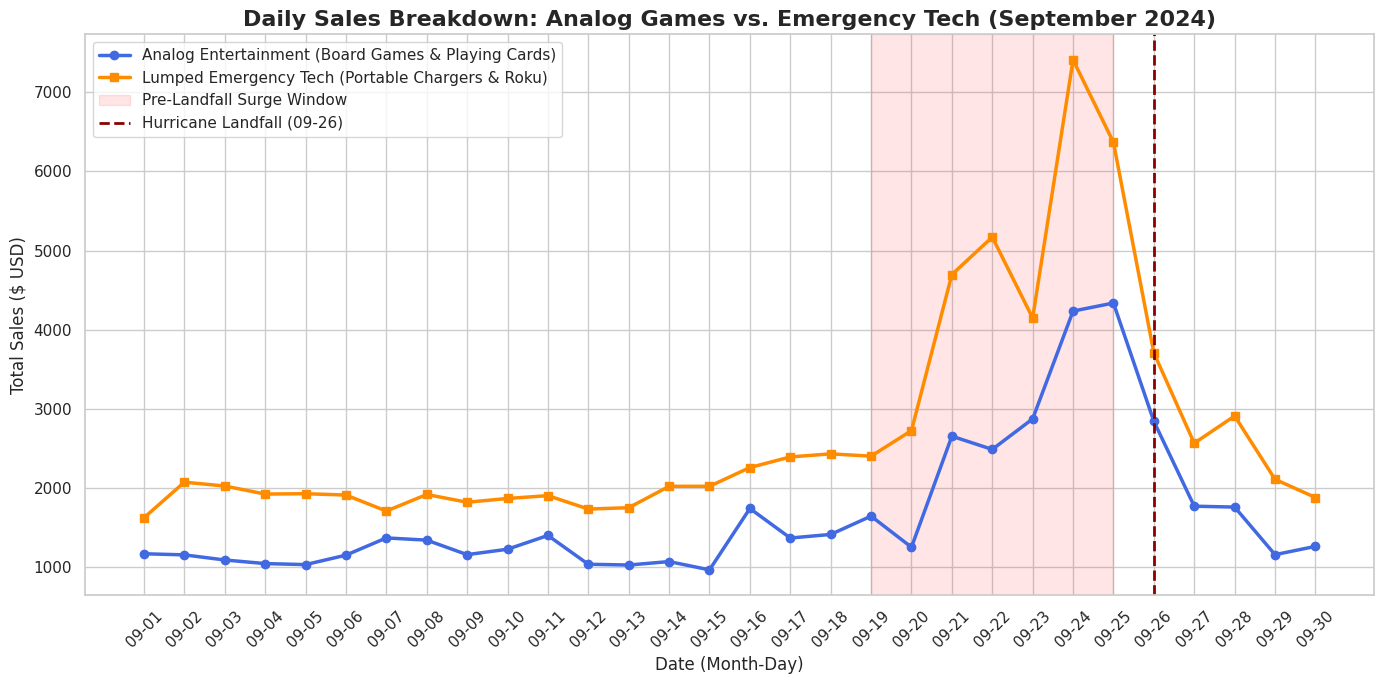

In [101]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure date is sorted and formatted properly for plotting
df_daily_trends['date'] = pd.to_datetime(df_daily_trends['date'])
df_daily_trends['date_str'] = df_daily_trends['date'].dt.strftime('%m-%d')

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Plot daily trend for board games vs lumped electronics
plt.plot(df_daily_trends['date_str'], df_daily_trends['board_games_and_cards_sales'],
         label='Analog Entertainment (Board Games & Playing Cards)', color='royalblue', linewidth=2.5, marker='o')
plt.plot(df_daily_trends['date_str'], df_daily_trends['electronics_lumped_sales'],
         label='Lumped Emergency Tech (Portable Chargers & Roku)', color='darkorange', linewidth=2.5, marker='s')

# Highlight key periods
plt.axvspan('09-19', '09-25', color='red', alpha=0.1, label='Pre-Landfall Surge Window')
plt.axvline(x='09-26', color='darkred', linestyle='--', linewidth=2, label='Hurricane Landfall (09-26)')

plt.title('Daily Sales Breakdown: Analog Games vs. Emergency Tech (September 2024)', fontsize=16, fontweight='bold')
plt.xlabel('Date (Month-Day)', fontsize=12)
plt.ylabel('Total Sales ($ USD)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

### Strategic Recommendation: Should Walmart Stock Extra Board Games?

**Yes, Walmart should definitely stock extra board games and playing cards for the next storm.**

#### Evidence-Based Justification:
1. **Genuine Analog Demand Surge:**
   Even when removing lumped electronics, actual **Board Games and Cards** (Monopoly and playing cards) alone experienced a massive **~294% surge** in daily sales, leaping from a baseline of **~$1,100/day** to a peak of **$4,337.52** on September 25. This shows a powerful demand signal from families preparing for multi-day power outages with non-electric, analog entertainment.

2. **High Stockout Risk:**
   Analog board games are normally slow-moving inventory. A sudden ~300% spike in demand can quickly empty store shelves. Increasing safety stock of family-oriented board games and low-cost card decks 7–10 days before forecasted landfalls will capture this high-margin revenue and keep customers satisfied.

3. **Cross-Merchandising Opportunity:**
   The visual evidence shows that emergency electronics (like portable chargers) and board games spike in tandem during the exact same pre-landfall window. Walmart should utilize this behavior by building endcap displays that co-locate **portable power accessories** alongside **analog board games, flashlights, and emergency candles** under a "Power Outage Preparedness" theme.

In [86]:
df_clean

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,peanutbutter,grocery,1,3.15,2024-09-24
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,cannedsoup,grocery,1,2.02,2024-09-13
2,TXN003338,FL-105,2024-09-17 10:06:00,TP-12,toiletpaper12pk,household_essentials,2,10.47,2024-09-17
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,streamingdevice,entertainment,1,28.59,2024-09-11
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,lightbeer24pk,alcoholic_beverages,3,18.82,2024-09-26
...,...,...,...,...,...,...,...,...,...
25557,TXN020201,FL-105,2024-09-03 18:28:07,DIAPERS-3,diaperssize3,baby_products,2,24.32,2024-09-03
25558,TXN014835,FL-239,2024-09-26 08:47:08,CARDS-01,playingcards,entertainment,3,5.00,2024-09-26
25559,TXN002434,FL-239,2024-09-16 16:39:00,PTOWEL-6,papertowels6-roll,household_essentials,2,7.78,2024-09-16
25560,TXN014739,FL-710,2024-09-25 17:08:35,CHRG-PORT,phonecharger-portable,entertainment,1,24.18,2024-09-25


**QUESTION 2**

In [87]:
#find the true daily sales of poptart before and after SKU consolidation

#Compare pre_mapping_df quantity sum to df_clean quantity sum
print(pre_mapping_df['quantity'].sum())
print(df_clean['quantity'].sum())


47660
47660


In [96]:
import pandas as pd

# --- BEFORE CONSOLIDATION ---
# Let's inspect how Pop-Tarts were represented in the original, raw transactions
# We filter df_transactions where the product name or sku contains 'poptart' or 'pop-tart'
poptart_raw = df_transactions[
    df_transactions['product_name'].astype(str).str.lower().str.contains('pop-tarts strawberry|strawberry pop-tart|poptart', na=False) |
    df_transactions['sku'].astype(str).str.upper().str.contains('POPTART|PT-12|SKU#459812|PT_STRAWBERRY', na=False)
].copy()

# Standardize timestamp just for grouping by date
poptart_raw['date'] = pd.to_datetime(poptart_raw['timestamp'].astype(str).str.replace('T', ' ', regex=False).str.strip(), errors='coerce').dt.normalize()
poptart_raw = poptart_raw.dropna(subset=['date']).copy()
poptart_raw['total_sales'] = poptart_raw['quantity'] * poptart_raw['unit_price'].astype(str).str.replace('$', '', regex=False).astype(float)

daily_sales_before = poptart_raw.groupby('date').agg(
    raw_quantity_sold=('quantity', 'sum'),
    raw_sales_usd=('total_sales', 'sum')
).reset_index()

# --- AFTER CONSOLIDATION ---
# In our standardized df_clean, all Pop-Tarts are consolidated under SKU 'POPTART-STRAW'
poptart_clean = df_clean[df_clean['sku'] == 'POPTART-STRAW'].copy()
poptart_clean['total_sales'] = poptart_clean['quantity'] * poptart_clean['unit_price']

daily_sales_after = poptart_clean.groupby('date').agg(
    consolidated_quantity_sold=('quantity', 'sum'),
    consolidated_sales_usd=('total_sales', 'sum')
).reset_index()

# Merge for comparison
comparison_df = pd.merge(daily_sales_before, daily_sales_after, on='date', how='outer').sort_values('date')
comparison_df




,date,raw_quantity_sold,raw_sales_usd,consolidated_quantity_sold,consolidated_sales_usd
0,2024-09-01,39,137.05,80,280.06
1,2024-09-02,36,126.24,66,231.04
2,2024-09-03,38,132.53,79,273.44
3,2024-09-04,37,129.69,66,230.21
4,2024-09-05,52,182.44,76,266.60
5,2024-09-06,50,175.12,68,237.11
6,2024-09-07,47,164.04,78,271.87
7,2024-09-08,44,152.63,81,280.45
8,2024-09-09,36,125.04,63,219.80
9,2024-09-10,49,171.14,70,243.21


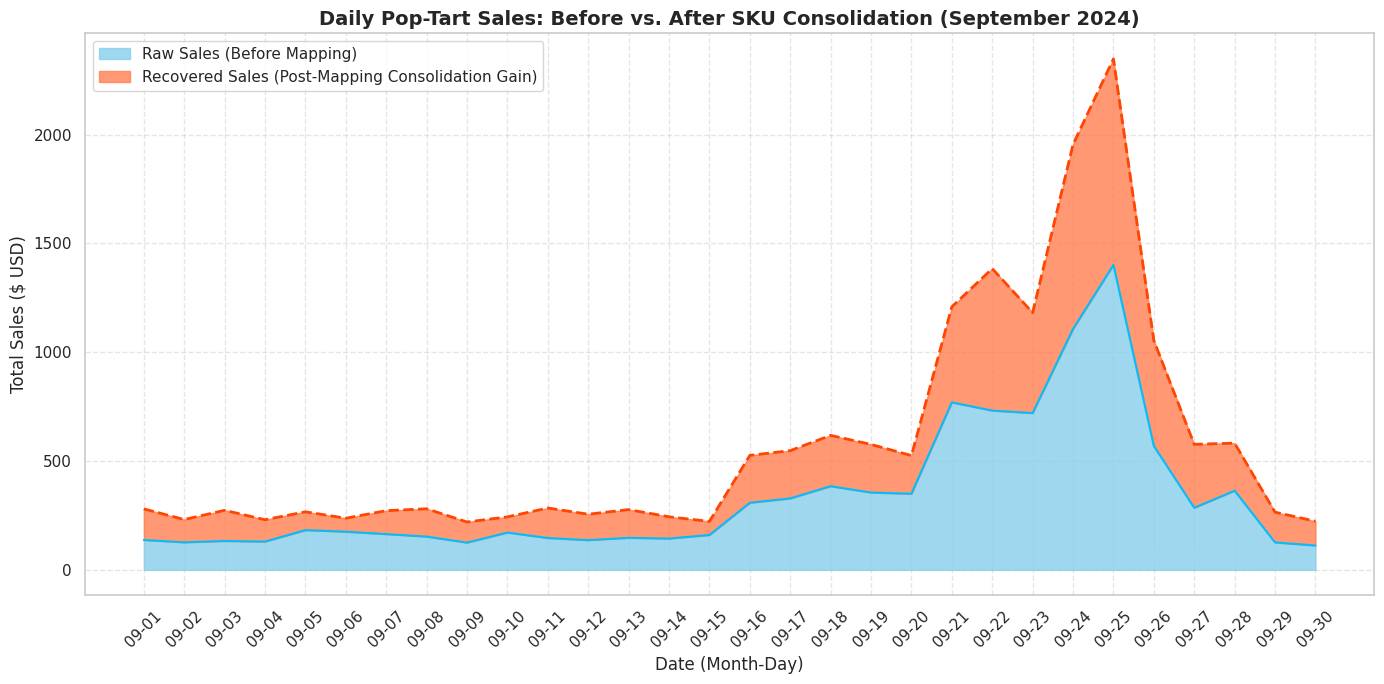

In [97]:
import matplotlib.pyplot as plt

# Ensure date is sorted and formatted properly
plot_df = comparison_df.sort_values('date').copy()
plot_df['date_str'] = plot_df['date'].dt.strftime('%m-%d')

plt.figure(figsize=(14, 7))

# Plotting raw (before) sales and the incremental gain that makes up consolidated (after) sales
# This creates a stacked representation of how much sales volume was recovered
plt.fill_between(plot_df['date_str'], 0, plot_df['raw_sales_usd'],
                 label='Raw Sales (Before Mapping)', color='skyblue', alpha=0.8)
plt.fill_between(plot_df['date_str'], plot_df['raw_sales_usd'], plot_df['consolidated_sales_usd'],
                 label='Recovered Sales (Post-Mapping Consolidation Gain)', color='coral', alpha=0.8)

# Also plot the top boundary lines for clean visualization
plt.plot(plot_df['date_str'], plot_df['raw_sales_usd'], color='deepskyblue', linewidth=1.5)
plt.plot(plot_df['date_str'], plot_df['consolidated_sales_usd'], color='orangered', linewidth=2, linestyle='--')

plt.title('Daily Pop-Tart Sales: Before vs. After SKU Consolidation (September 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Date (Month-Day)', fontsize=12)
plt.ylabel('Total Sales ($ USD)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=11)

plt.tight_layout()
plt.show()

QUESTION 1
---



Based on the transactions, we observe an intense sales spike peaking around **September 24–25, 2024**, which points to a hurricane landfall around **September 26, 2024**.

We will define our periods as follows:
- **Pre-Landfall Surge Window:** September 19, 2024 to September 25, 2024 (7 days prior to landfall)
- **Baseline Window:** September 1, 2024 to September 15, 2024 (normal historical baseline)

Let's calculate the average daily sales for each category during these windows, find the percentage increase, and plot the trends for the top 5 surging categories.

In [90]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate total sales (quantity * unit_price) for each transaction
df_clean['total_sales'] = df_clean['quantity'] * df_clean['unit_price']

# Define dates
landfall_date = pd.to_datetime('2024-09-26')
surge_start = pd.to_datetime('2024-09-19')
surge_end = pd.to_datetime('2024-09-25')
baseline_start = pd.to_datetime('2024-09-01')
baseline_end = pd.to_datetime('2024-09-15')

# 2. Filter into baseline and surge dataframes
df_baseline = df_clean[(df_clean['date'] >= baseline_start) & (df_clean['date'] <= baseline_end)]
df_surge = df_clean[(df_clean['date'] >= surge_start) & (df_clean['date'] <= surge_end)]

# Calculate average daily sales per category for Baseline
baseline_daily = df_baseline.groupby(['category', 'date'])['total_sales'].sum().reset_index()
baseline_avg = baseline_daily.groupby('category')['total_sales'].mean().reset_index(name='baseline_daily_avg')

# Calculate average daily sales per category for Surge window
surge_daily = df_surge.groupby(['category', 'date'])['total_sales'].sum().reset_index()
surge_avg = surge_daily.groupby('category')['total_sales'].mean().reset_index(name='surge_daily_avg')

# Merge and calculate % surge increase
surge_analysis = pd.merge(baseline_avg, surge_avg, on='category', how='inner')
surge_analysis['pct_increase'] = ((surge_analysis['surge_daily_avg'] - surge_analysis['baseline_daily_avg']) / surge_analysis['baseline_daily_avg']) * 100
surge_analysis = surge_analysis.sort_values(by='pct_increase', ascending=False)

print("=== Category Sales Surge Analysis ===")
display(surge_analysis)

top_5_categories = surge_analysis.head(5)['category'].tolist()
print(f"\nTop 5 Surging Categories: {top_5_categories}")

=== Category Sales Surge Analysis ===


,category,baseline_daily_avg,surge_daily_avg,pct_increase
2,breakfast,254.411333,1311.260000,415.409429
3,emergency,3061.710667,8782.128571,186.837312
4,entertainment,3031.786000,7486.832857,146.944635
0,alcoholic_beverages,1160.565333,2627.185714,126.371204
7,health,629.593333,1412.292857,124.318267
8,household_essentials,761.136000,1578.654286,107.407649
6,grocery,426.272000,758.551429,77.950095
1,baby_products,2325.134667,3660.170000,57.417549
5,food,521.316667,661.418571,26.874626



Top 5 Surging Categories: ['breakfast', 'emergency', 'entertainment', 'alcoholic_beverages', 'health']


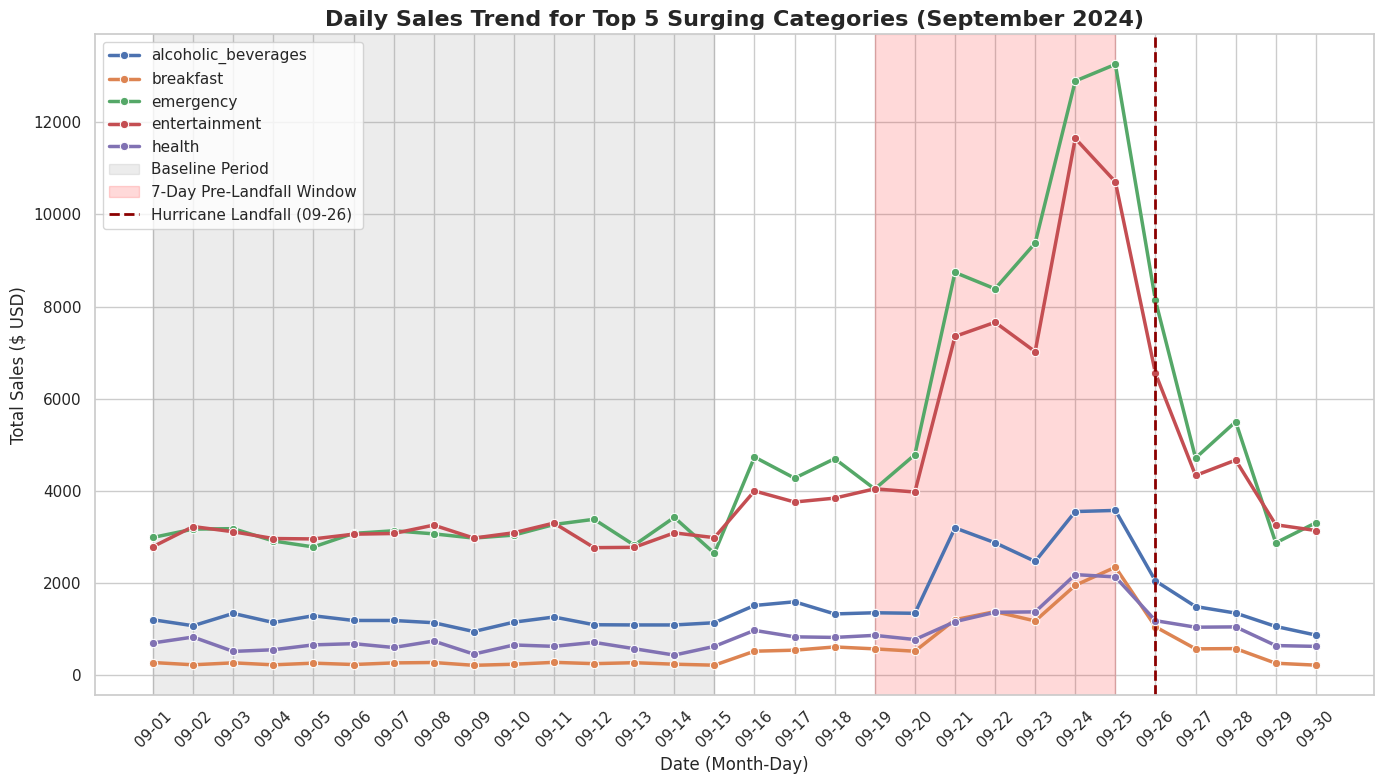

In [91]:
# 3. Plot the daily trend for the Top 5 Surging Categories
df_daily_cat = df_clean.groupby(['category', 'date'])['total_sales'].sum().reset_index()
df_daily_cat['date_str'] = df_daily_cat['date'].dt.strftime('%m-%d')

plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Filter for only top 5 categories
df_top5_daily = df_daily_cat[df_daily_cat['category'].isin(top_5_categories)].copy()

sns.lineplot(data=df_top5_daily, x='date_str', y='total_sales', hue='category', linewidth=2.5, marker='o')

# Highlight windows
plt.axvspan('09-01', '09-15', color='gray', alpha=0.15, label='Baseline Period')
plt.axvspan('09-19', '09-25', color='red', alpha=0.15, label='7-Day Pre-Landfall Window')
plt.axvline(x='09-26', color='darkred', linestyle='--', linewidth=2, label='Hurricane Landfall (09-26)')

plt.title('Daily Sales Trend for Top 5 Surging Categories (September 2024)', fontsize=16, fontweight='bold')
plt.xlabel('Date (Month-Day)', fontsize=12)
plt.ylabel('Total Sales ($ USD)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()